# Neural Network
## By Group 1

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor
from sklearn.model_selection import train_test_split
import torch.optim as optim
import torch.nn as nn
import torch
import csv
import math

%matplotlib inline


torch.manual_seed(0)


%load_ext autoreload
%autoreload 2

from sklearn.metrics import classification_report, accuracy_score
from sklearn.model_selection import ParameterGrid

We prepare the data from existing dataset using the load_or_cache function. It uses a csv file to parse through image dataset on what belongs to each stage of the process based on the data splitting that was done in the EDA as part of the pre-processing.

In [ ]:
def load_or_cache(split, folder, csv_path, cache_dir="cache", size=(224, 224), batch=1000, workers=8):
    os.makedirs(cache_dir, exist_ok=True)
    xp = os.path.join(cache_dir, f"X_{split}_{size[0]}.npy")
    yp = os.path.join(cache_dir, f"y_{split}_{size[0]}.npy")

    if os.path.exists(xp) and os.path.exists(yp):
        return np.load(xp), np.load(yp)

    df = pd.read_csv(csv_path, usecols=["filename", "category_id"])
    files = df["filename"].astype(str).values
    y = df["category_id"].values.astype(int)
    
    def read(f):
        path = os.path.join(folder, f)
        img = cv2.imread(path)

        if img is None:
            raise ValueError(f"Could not read image: {path}")

        return cv2.resize(img, size, interpolation=cv2.INTER_AREA).ravel()

    X = np.empty((len(files), size[0] * size[1] * 3), np.uint8)
    with ThreadPoolExecutor(workers) as ex:
        for i in range(0, len(files), batch):
            X[i:i + batch] = list(ex.map(read, files[i:i + batch]))

    np.save(xp, X)
    np.save(yp, y)
    return X, y

In [ ]:
folder = "dataset_updated/224x224"

In [ ]:
X_train, y_train = load_or_cache("train", folder, "dataset_updated/train/listings_train.csv")    

In [ ]:
X_val, y_val = load_or_cache("val", folder, "dataset_updated/validation/listings_val.csv")

In [ ]:
X_test, y_test = load_or_cache("test", folder, "dataset_updated/test/listings_test.csv")

After splitting the data into training, validation, and testing sets, we extracted the features of the images using the colored color Histogram, and we start preparing the data 

In [ ]:
def extract_features(flat, size=224, bins=8):
    img = flat.reshape(size, size, 3)

    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    c = cv2.calcHist([hsv], [0, 1, 2], None, [bins]*3,
                     [0, 180, 0, 256, 0, 256]).ravel()
    c /= max(c.sum(), 1)

    return np.sqrt(c).astype(np.float32)

In [ ]:
def load_or_cache_features(split, X, extract_features, workers=8, cache_dir="cache", feature_name="color_histogram"):
    os.makedirs(cache_dir, exist_ok=True)
    xp = os.path.join(cache_dir, f"X_{split}_{feature_name}.npy")

    if os.path.exists(xp):
        print(f"Loading cached {split} features...")
        return np.load(xp)

    print(f"Extracting {split} features...")
    with ThreadPoolExecutor(max_workers=workers) as ex:
        X_features = np.array(list(ex.map(extract_features, X)), dtype=np.float32)

    np.save(xp, X_features)
    print(f"Saved {split} features to {xp}")
    return X_features

In [ ]:
X_train_features = load_or_cache_features("train", X_train, extract_features)
X_val_features = load_or_cache_features("val", X_val, extract_features)
X_test_features = load_or_cache_features("test", X_test, extract_features)

Loading cached train features...
Loading cached val features...
Loading cached test features...


In [ ]:
X_train_features = torch.tensor(X_train_features)
X_val_features = torch.tensor(X_val_features)
X_test_features = torch.tensor(X_test_features)

In [ ]:
y_train = torch.tensor(y_train)
y_val = torch.tensor(y_val)
y_test = torch.tensor(y_test)

After preparing our data for neural network, we then create the baseline neural network architecture and functions needed to execute the process. The evaluate function just returns the losses and accuracy of the model. The make_scheduler function is to ensure that the hyperparameter of learning schedule will be able to function well, and the train_model function creates the neural network architecture and performs the model training.

Since the classes has 512 features, we have 512 input nodes to match it accordingly. We have 30 nodes in the output layer since the data has 30 classes before undergoing a softmax node to determine which class an input would be. The hidden layer would be part of the hyperparameters to identify whether the model needs deep layers to understand the images better

In [ ]:
from neural_network import NeuralNetwork

In [ ]:
import copy
from torch.utils.data import DataLoader, TensorDataset

device = "cuda" if torch.cuda.is_available() else "cpu"

def evaluate(model, criterion, X, y):
    model.eval()
    with torch.no_grad():
        logits, probs = model(X.to(device))
        yb = y.to(device)
        return criterion(logits, yb).item(), (model.predict(probs) == yb).float().mean().item()


def make_scheduler(name, optimizer, max_epochs, lr, steps_per_epoch):
    if name == "step":
        return optim.lr_scheduler.StepLR(optimizer, step_size=max_epochs // 3, gamma=0.3)
    if name == "cosine":
        return optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max_epochs)
    return None

In [ ]:
def train_model(params, max_epochs=60, patience=8, verbose=False):
    network = NeuralNetwork(512, 30, params["list_hidden"], activation=params["activation"], dropout=params["dropout"])
    network.create_network()
    network.init_weights()
    network.to(device)
    
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = optim.AdamW(network.parameters(), lr=params["lr"], weight_decay=params["weight_decay"])
    dl = DataLoader(TensorDataset(X_train_features, y_train), batch_size=params["batch_size"], shuffle=True)
    scheduler = make_scheduler(params["scheduler"], optimizer, max_epochs, params["lr"], len(dl))


    best_acc, best_state, best_epoch, wait, history = 0.0, None, 0, 0, []
    for epoch in range(max_epochs):
        network.train()
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits, _ = network(xb)
            criterion(logits, yb).backward()
            optimizer.step()


        tr_loss, tr_acc = evaluate(network, criterion, X_train_features, y_train)
        va_loss, va_acc = evaluate(network, criterion, X_val_features, y_val)
        history.append((tr_loss, tr_acc, va_loss, va_acc))


        if params["scheduler"] in ("step", "cosine"): scheduler.step()


        if va_acc > best_acc:
            best_acc, best_state, best_epoch, wait = va_acc, copy.deepcopy(network.state_dict()), epoch + 1, 0
        else:
            wait += 1
            if wait >= patience:
                break

    network.load_state_dict(best_state)
    return network, best_acc, best_epoch, history

In the base model that will be created, there are 3 hidden layers since image data tends to be complex with the number of nodes dropping across the hidden layers. In this model, we will use a learning rate of 0.001 since it is the standard for the Adam Optimizer (the selected optimizer for this model).

The baseline model will also use a weight decay value of 0.01 since it works fine with Adam optimizer in preventing the model from overfitting towards the training data. We use a dropout of 0.3 since this is the standard dropout value for MLP neural networks. Relu is our activation function since it the industry standard as well. To have a more neutral base model, the learning rate schedule will be set to none (constant learning)

In [36]:
base = {"list_hidden": [256, 128,64], "lr": 1e-3, "dropout": 0.3,
        "weight_decay": 1e-2, "batch_size": 128, "activation": "relu", "scheduler":"none"}
model, acc, ep, hist = train_model(base, verbose=True)
print(acc)

0.14614035189151764


In [ ]:
param_grid = {
    "list_hidden": [[256, 128], [256, 128, 64]],
    "lr": [1e-4, 1e-3],
    "dropout": [0.2, 0.4],
    "weight_decay": [1e-2],
    "batch_size": [128],
    "activation": ["relu"],
    "scheduler": ["none", "step", "cosine"],
}

results = []
for i, p in enumerate(ParameterGrid(param_grid), 1):
    _, acc, ep, hist = train_model(p)
    results.append({**p, "list_hidden": str(p["list_hidden"]),
                    "val_acc": acc, "best_epoch": ep, "train_acc": hist[-1][1]})
    print(i, f"{acc:.4f}", p)

results_df = pd.DataFrame(results).sort_values("val_acc", ascending=False)
results_df.head(5)

1 0.1425 {'activation': 'relu', 'batch_size': 128, 'dropout': 0.2, 'list_hidden': [256, 128], 'lr': 0.0001, 'scheduler': 'none', 'weight_decay': 0.01}
2 0.1340 {'activation': 'relu', 'batch_size': 128, 'dropout': 0.2, 'list_hidden': [256, 128], 'lr': 0.0001, 'scheduler': 'step', 'weight_decay': 0.01}
3 0.1354 {'activation': 'relu', 'batch_size': 128, 'dropout': 0.2, 'list_hidden': [256, 128], 'lr': 0.0001, 'scheduler': 'cosine', 'weight_decay': 0.01}
4 0.1526 {'activation': 'relu', 'batch_size': 128, 'dropout': 0.2, 'list_hidden': [256, 128], 'lr': 0.001, 'scheduler': 'none', 'weight_decay': 0.01}
5 0.1518 {'activation': 'relu', 'batch_size': 128, 'dropout': 0.2, 'list_hidden': [256, 128], 'lr': 0.001, 'scheduler': 'step', 'weight_decay': 0.01}
6 0.1526 {'activation': 'relu', 'batch_size': 128, 'dropout': 0.2, 'list_hidden': [256, 128], 'lr': 0.001, 'scheduler': 'cosine', 'weight_decay': 0.01}
7 0.1433 {'activation': 'relu', 'batch_size': 128, 'dropout': 0.2, 'list_hidden': [256, 128, 

,activation,batch_size,dropout,list_hidden,lr,scheduler,weight_decay,val_acc,best_epoch,train_acc
17,relu,128,0.4,"[256, 128]",0.001,cosine,0.01,0.155789,32,0.257057
16,relu,128,0.4,"[256, 128]",0.001,step,0.01,0.155263,37,0.251025
15,relu,128,0.4,"[256, 128]",0.001,none,0.01,0.154561,21,0.241134
3,relu,128,0.2,"[256, 128]",0.001,none,0.01,0.152632,24,0.330095
5,relu,128,0.2,"[256, 128]",0.001,cosine,0.01,0.152632,25,0.315926


The results from the hyper parameter tuning showed that the best peforming model was a neural network model with the following parameters:

* activation: relu, 
* batch size: 128, 
* dropout: 0.4, 
* hidden layer architecture: 256 nodes in the first hidden layer, 128 nodes in the second hidden layer,
* learning rate: 0.001
* scheduler: Cosine Annealing for the learning rate schedule, 
* weight decay: 0.01

From here we can see that the differences between each model in the validation accuracy is small. From the best 5 models, we can infer that the network prefers taking relatively larger steps since the 0.0004 was not in any of the best 5 models. Using the same parameters, we can observe that there are minimal differences as well with the learning schedule hyperparameter, especially between cosine and step. 

All the best models also had a dropout of 0.4 but it is a slight improvement over other models with similar parameters. This implies that having a relatively larger percentage of nodes being turned off to prevent overfitting does help the validation set accuracy

We now proceed to plotting the loss of the best model in order to examine overfitting or underfitting

In [40]:
def plot_history(history, title="Training curves", best_epoch=None):
    tr_loss, tr_acc, va_loss, va_acc = zip(*history)
    epochs = range(1, len(history) + 1)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    ax1.plot(epochs, tr_loss, label="Train loss")
    ax1.plot(epochs, va_loss, label="Validation loss")
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("Loss")
    ax1.set_title("Loss")

    ax2.plot(epochs, tr_acc, label="Train accuracy")
    ax2.plot(epochs, va_acc, label="Validation accuracy")
    ax2.set_xlabel("Epoch")
    ax2.set_ylabel("Accuracy")
    ax2.set_title("Accuracy")

    if best_epoch is not None:
        ax1.axvline(best_epoch, color="gray", linestyle="--", label=f"Best epoch ({best_epoch})")
        ax2.axvline(best_epoch, color="gray", linestyle="--")

    ax1.legend()
    ax2.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

Best val accuracy: 0.1558 at epoch 32


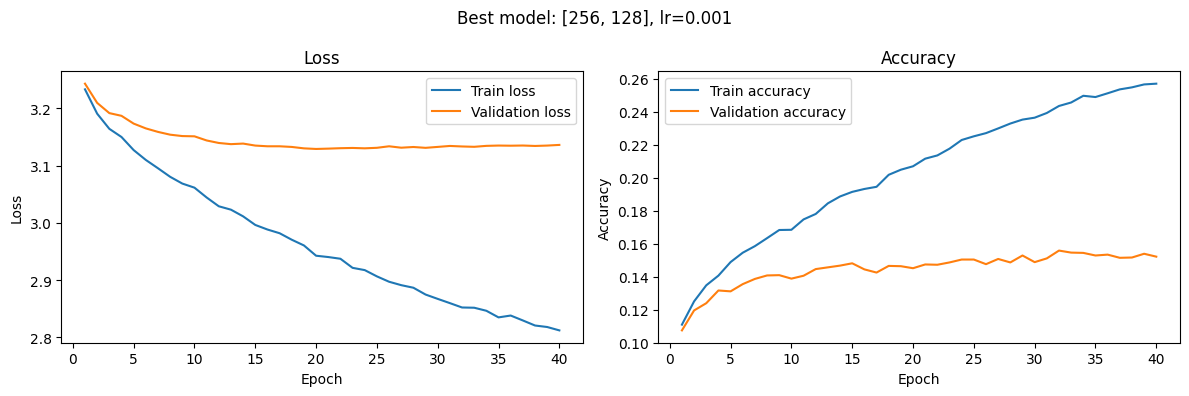

In [41]:
best_model_params = {"list_hidden": [256, 128], "lr": 1e-3, "dropout": 0.4,
        "weight_decay": 1e-2, "batch_size": 128, "activation": "relu", "scheduler":"cosine"}
best_model, best_val_acc, best_epoch, best_hist = train_model(best_model_params, max_epochs=60, patience=8)

print(f"Best val accuracy: {best_val_acc:.4f} at epoch {best_epoch}")
plot_history(best_hist, title=f"Best model: {best_model_params['list_hidden']}, lr={best_model_params['lr']}")

From the graph, we can observe that there is a chance that the model is overfitted to the training data since the train loss falls while the validation loss flattens. This can also be seen in the accuracy where the training accuracy increases, but the validation accuracy stagnates. 

From here, we performed further hyperparameter tuning, specifically for regularization, to check whether or not this is a result of the model features being insufficient or if the model really is just overfitted. We tuned the parameters related to regularization and used the best model's parameters for the other parameters.

In [ ]:
param_grid = {
    "list_hidden": [[256, 128]],
    "lr": [1e-3],
    "dropout": [0.2, 0.4, 0.6],
    "weight_decay": [1e-4,1e-3,1e-2,1e-1],
    "batch_size": [128],
    "activation": ["relu"],
    "scheduler": ["cosine"],
}

results = []
for i, p in enumerate(ParameterGrid(param_grid), 1):
    _, acc, ep, hist = train_model(p)
    results.append({**p, "list_hidden": str(p["list_hidden"]),
                    "val_acc": acc, "best_epoch": ep, "train_acc": hist[-1][1]})
    print(i, f"{acc:.4f}", p)

results_df = pd.DataFrame(results).sort_values("val_acc", ascending=False)
results_df.head(5)

1 0.1553 {'activation': 'relu', 'batch_size': 128, 'dropout': 0.2, 'list_hidden': [256, 128], 'lr': 0.001, 'scheduler': 'cosine', 'weight_decay': 0.0001}
2 0.1512 {'activation': 'relu', 'batch_size': 128, 'dropout': 0.2, 'list_hidden': [256, 128], 'lr': 0.001, 'scheduler': 'cosine', 'weight_decay': 0.001}
3 0.1526 {'activation': 'relu', 'batch_size': 128, 'dropout': 0.2, 'list_hidden': [256, 128], 'lr': 0.001, 'scheduler': 'cosine', 'weight_decay': 0.01}
4 0.1505 {'activation': 'relu', 'batch_size': 128, 'dropout': 0.2, 'list_hidden': [256, 128], 'lr': 0.001, 'scheduler': 'cosine', 'weight_decay': 0.1}
5 0.1546 {'activation': 'relu', 'batch_size': 128, 'dropout': 0.4, 'list_hidden': [256, 128], 'lr': 0.001, 'scheduler': 'cosine', 'weight_decay': 0.0001}
6 0.1558 {'activation': 'relu', 'batch_size': 128, 'dropout': 0.4, 'list_hidden': [256, 128], 'lr': 0.001, 'scheduler': 'cosine', 'weight_decay': 0.001}
7 0.1558 {'activation': 'relu', 'batch_size': 128, 'dropout': 0.4, 'list_hidden': [

,activation,batch_size,dropout,list_hidden,lr,scheduler,weight_decay,val_acc,best_epoch,train_acc
6,relu,128,0.4,"[256, 128]",0.001,cosine,0.0100,0.155789,32,0.257057
5,relu,128,0.4,"[256, 128]",0.001,cosine,0.0010,0.155789,33,0.264427
0,relu,128,0.2,"[256, 128]",0.001,cosine,0.0001,0.155263,25,0.319391
4,relu,128,0.4,"[256, 128]",0.001,cosine,0.0001,0.154561,23,0.241550
2,relu,128,0.2,"[256, 128]",0.001,cosine,0.0100,0.152632,25,0.315926


In [43]:
results_df

,activation,batch_size,dropout,list_hidden,lr,scheduler,weight_decay,val_acc,best_epoch,train_acc
6,relu,128,0.4,"[256, 128]",0.001,cosine,0.0100,0.155789,32,0.257057
5,relu,128,0.4,"[256, 128]",0.001,cosine,0.0010,0.155789,33,0.264427
0,relu,128,0.2,"[256, 128]",0.001,cosine,0.0001,0.155263,25,0.319391
4,relu,128,0.4,"[256, 128]",0.001,cosine,0.0001,0.154561,23,0.241550
2,relu,128,0.2,"[256, 128]",0.001,cosine,0.0100,0.152632,25,0.315926
7,relu,128,0.4,"[256, 128]",0.001,cosine,0.1000,0.151930,14,0.194920
1,relu,128,0.2,"[256, 128]",0.001,cosine,0.0010,0.151228,15,0.274647
3,relu,128,0.2,"[256, 128]",0.001,cosine,0.1000,0.150526,14,0.233983
8,relu,128,0.6,"[256, 128]",0.001,cosine,0.0001,0.147018,41,0.204439
11,relu,128,0.6,"[256, 128]",0.001,cosine,0.1000,0.145965,43,0.191235


After examining the performances of the hyperparameter tuning, the original best model still had the smallest gap between the training accuracy and the validation accuracy. Tweaking the regularization parameters bare changed the validation accuracy's performance with higher regularization leading to lower validation accuracy. This implies that the model performance is hindered by the features rather than the regularization parameters.

### AI Usage

* Used Claude to find a way to use optimize computational usage in training the model
* Used Claude to optimize the model training codes and make it cleaner.
* Used Claude to suggest on handling overfitting